<a href="https://colab.research.google.com/github/AdityaMall1093/Energy-Theft-Ai/blob/main/final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('/content/data set.csv')

In [3]:
df.head()

,1/1/2014,1/2/2014,1/3/2014,1/4/2014,1/5/2014,1/6/2014,1/7/2014,1/8/2014,1/9/2014,1/10/2014,...,10/24/2016,10/25/2016,10/26/2016,10/27/2016,10/28/2016,10/29/2016,10/30/2016,10/31/2016,CONS_NO,FLAG
0,0,0.0,0.01,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,0.02,0.06,0.58,0.89,0.35,0.38,0.70,0.25,0387DD8A07E07FDA6271170F86AD9151,1.0
1,0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,17.13,14.32,16.37,26.33,19.06,17.38,13.94,14.14,01D6177B5D4FFE0CABA9EF17DAFC2B84,1.0
2,0,0.0,0.00,0.0,0.0,4.98,9.87,11.29,13.44,11.34,...,NaN,1.43,2.22,2.41,3.48,2.89,1.88,1.16,4B75AC4F2D8434CFF62DB64D0BB43103,1.0
3,0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,20.98,18.47,15.50,14.80,19.28,16.10,17.51,16.67,B32AC8CC6D5D805AC053557AB05F5343,1.0
4,0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,0.61,1.33,0.55,1.62,1.53,2.10,1.16,2.13,EDFC78B07BA2908B3395C4EB2304665E,1.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2275 entries, 0 to 2274
Columns: 1036 entries, 1/1/2014 to FLAG
dtypes: float64(1034), int64(1), object(1)
memory usage: 18.0+ MB


In [5]:
df.describe()

,1/1/2014,1/2/2014,1/3/2014,1/4/2014,1/5/2014,1/6/2014,1/7/2014,1/8/2014,1/9/2014,1/10/2014,...,10/23/2016,10/24/2016,10/25/2016,10/26/2016,10/27/2016,10/28/2016,10/29/2016,10/30/2016,10/31/2016,FLAG
count,2275.0,2273.000000,2270.000000,2272.000000,2272.000000,2272.000000,2272.000000,2274.000000,2273.000000,2273.000000,...,2244.000000,2250.000000,2243.000000,2241.000000,2237.000000,2238.000000,2227.000000,2226.000000,2234.000000,2274.000000
mean,0.0,1.266837,1.591251,1.704551,1.781774,1.961444,5.216699,2.283980,2.279657,2.195433,...,9.843061,8.499809,8.897316,9.314261,9.946165,10.097962,9.072259,8.411986,7.910815,0.228672
std,0.0,5.451150,6.971260,6.903425,7.246863,7.729589,149.559984,8.831952,8.911309,8.844625,...,55.754019,51.122410,52.289439,55.916002,58.734554,57.634730,52.751527,49.706023,48.179226,0.420070
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,2.325000,2.150000,2.150000,2.260000,2.370000,2.500000,2.160000,2.195000,2.235000,0.000000
75%,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,8.500000,7.472500,7.595000,7.970000,8.500000,8.335000,7.845000,7.440000,6.987500,0.000000
max,0.0,118.790000,173.060000,187.910000,197.530000,190.470000,7119.810000,184.650000,183.820000,178.770000,...,2198.800000,2125.200000,2147.600000,2298.800000,2369.200000,2270.800000,2033.200000,1987.600000,1991.600000,1.000000


In [6]:
date_columns = df.columns.drop(['CONS_NO', 'FLAG'])
df_melted = df.melt(id_vars=['CONS_NO', 'FLAG'], value_vars=date_columns, var_name='Date', value_name='Consumption')
df_melted['Date'] = pd.to_datetime(df_melted['Date'], errors='coerce')
display(df_melted.head())

,CONS_NO,FLAG,Date,Consumption
0,0387DD8A07E07FDA6271170F86AD9151,1.0,2014-01-01,0.0
1,01D6177B5D4FFE0CABA9EF17DAFC2B84,1.0,2014-01-01,0.0
2,4B75AC4F2D8434CFF62DB64D0BB43103,1.0,2014-01-01,0.0
3,B32AC8CC6D5D805AC053557AB05F5343,1.0,2014-01-01,0.0
4,EDFC78B07BA2908B3395C4EB2304665E,1.0,2014-01-01,0.0


In [7]:
df_melted.info()
df_melted.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2352350 entries, 0 to 2352349
Data columns (total 4 columns):
 #   Column       Dtype         
---  ------       -----         
 0   CONS_NO      object        
 1   FLAG         float64       
 2   Date         datetime64[ns]
 3   Consumption  float64       
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 71.8+ MB


,FLAG,Date,Consumption
count,2.351316e+06,2352350,2.101170e+06
mean,2.286719e-01,2015-06-01 12:59:53.036750336,8.142620e+00
min,0.000000e+00,2014-01-01 00:00:00,0.000000e+00
25%,0.000000e+00,2014-09-16 00:00:00,0.000000e+00
50%,0.000000e+00,2015-06-01 12:00:00,8.300000e-01
75%,0.000000e+00,2016-02-15 00:00:00,6.760000e+00
max,1.000000e+00,2016-10-31 00:00:00,5.149918e+05
std,4.199776e-01,NaN,4.822887e+02


In [8]:
print('Missing values before treatment:')
print(df_melted.isnull().sum())

Missing values before treatment:
CONS_NO          1034
FLAG             1034
Date                0
Consumption    251180
dtype: int64


In [9]:
df_melted.dropna(subset=['CONS_NO', 'FLAG'], inplace=True)
df_melted['Consumption'] = df_melted.groupby('CONS_NO')['Consumption'].transform(lambda x: x.ffill().bfill())
print('Missing values after treatment:')
print(df_melted.isnull().sum())

Missing values after treatment:
CONS_NO        0
FLAG           0
Date           0
Consumption    0
dtype: int64


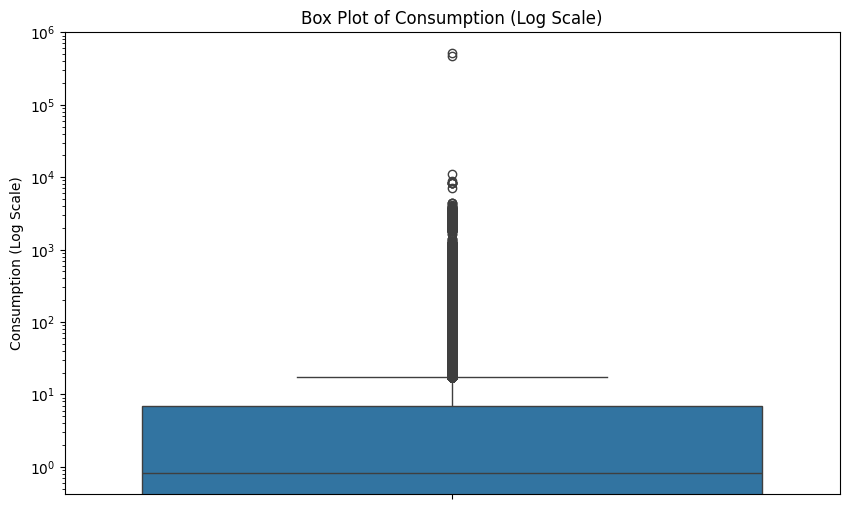

In [10]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df_melted['Consumption'])
plt.yscale('log')
plt.title('Box Plot of Consumption (Log Scale)')
plt.ylabel('Consumption (Log Scale)')
plt.show()

In [11]:
print('Skewness of Consumption:', df_melted['Consumption'].skew())

Skewness of Consumption: 1066.9968509177381


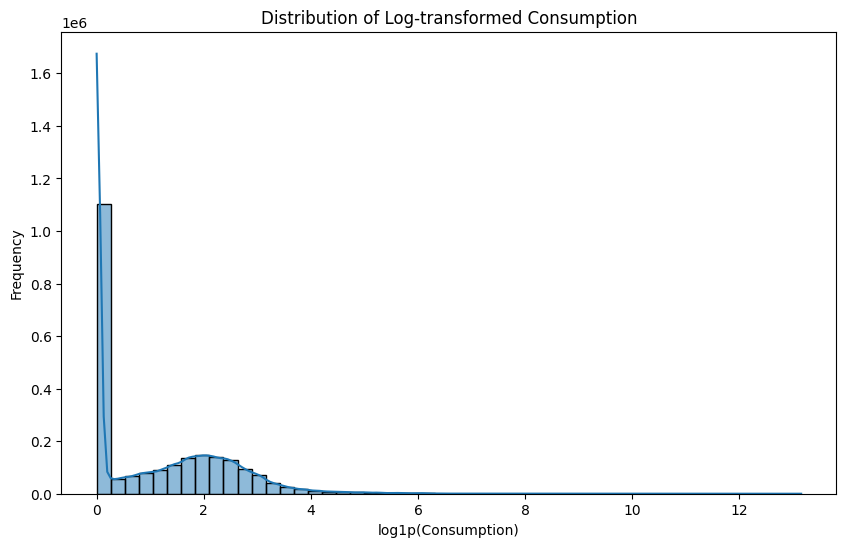

In [12]:
plt.figure(figsize=(10, 6))
sns.histplot(np.log1p(df_melted['Consumption']), bins=50, kde=True)
plt.title('Distribution of Log-transformed Consumption')
plt.xlabel('log1p(Consumption)')
plt.ylabel('Frequency')
plt.show()

In [13]:
zero_consumption_count = (df_melted['Consumption'] == 0).sum()
total_consumption_count = len(df_melted['Consumption'])
print(f"Number of zero consumption entries: {zero_consumption_count}")
print(f"Percentage of zero consumption entries: {((zero_consumption_count / total_consumption_count) * 100):.2f}%")

Number of zero consumption entries: 1009647
Percentage of zero consumption entries: 42.94%


In [14]:
df_melted['Year'] = df_melted['Date'].dt.year
df_melted['Month'] = df_melted['Date'].dt.month
df_melted['Day'] = df_melted['Date'].dt.day
df_melted['DayOfWeek'] = df_melted['Date'].dt.dayofweek
df_melted['DayOfYear'] = df_melted['Date'].dt.dayofyear
df_melted['WeekOfYear'] = df_melted['Date'].dt.isocalendar().week.astype(int)

display(df_melted.head())

,CONS_NO,FLAG,Date,Consumption,Year,Month,Day,DayOfWeek,DayOfYear,WeekOfYear
0,0387DD8A07E07FDA6271170F86AD9151,1.0,2014-01-01,0.0,2014,1,1,2,1,1
1,01D6177B5D4FFE0CABA9EF17DAFC2B84,1.0,2014-01-01,0.0,2014,1,1,2,1,1
2,4B75AC4F2D8434CFF62DB64D0BB43103,1.0,2014-01-01,0.0,2014,1,1,2,1,1
3,B32AC8CC6D5D805AC053557AB05F5343,1.0,2014-01-01,0.0,2014,1,1,2,1,1
4,EDFC78B07BA2908B3395C4EB2304665E,1.0,2014-01-01,0.0,2014,1,1,2,1,1


In [15]:
X = df_melted[['CONS_NO', 'FLAG', 'Year', 'Month', 'Day', 'DayOfWeek', 'DayOfYear', 'WeekOfYear']]
y = df_melted['Consumption']

print('Features (X) shape:', X.shape)
print('Target (y) shape:', y.shape)

display(X.head())
display(y.head())

Features (X) shape: (2351316, 8)
Target (y) shape: (2351316,)


,CONS_NO,FLAG,Year,Month,Day,DayOfWeek,DayOfYear,WeekOfYear
0,0387DD8A07E07FDA6271170F86AD9151,1.0,2014,1,1,2,1,1
1,01D6177B5D4FFE0CABA9EF17DAFC2B84,1.0,2014,1,1,2,1,1
2,4B75AC4F2D8434CFF62DB64D0BB43103,1.0,2014,1,1,2,1,1
3,B32AC8CC6D5D805AC053557AB05F5343,1.0,2014,1,1,2,1,1
4,EDFC78B07BA2908B3395C4EB2304665E,1.0,2014,1,1,2,1,1


,Consumption
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print('y_train shape:', y_train.shape)
print('y_test shape:', y_test.shape)

display(X_train.head())

X_train shape: (1881052, 8)
X_test shape: (470264, 8)
y_train shape: (1881052,)
y_test shape: (470264,)


,CONS_NO,FLAG,Year,Month,Day,DayOfWeek,DayOfYear,WeekOfYear
35227,F6772555361C15C8DC6A0DF9D8D65B30,0.0,2014,1,16,3,16,3
1355815,39B3623EAE5B51E8A48158759932B0D1,0.0,2015,8,19,2,231,34
2291690,21DEBE03EF52C05046D9E48C8089AE0E,0.0,2016,10,5,2,279,40
1676214,08B8E0F128725502C6C71643A3909988,0.0,2016,1,7,3,7,1
694066,12BC970F30356B88CFC8F226A79DE839,1.0,2014,11,2,6,306,44


In [17]:

y_train_binary = (y_train > 0).astype(int)
y_test_binary = (y_test > 0).astype(int)

print('Original y_train head:')
display(y_train.head())
print('\nBinary y_train_binary head:')
display(y_train_binary.head())

print('\nClass distribution in y_train_binary:')
print(y_train_binary.value_counts(normalize=True))

Original y_train head:


,Consumption
35227,0.00
1355815,4.10
2291690,11.35
1676214,0.40
694066,8.31



Binary y_train_binary head:


,Consumption
35227,0
1355815,1
2291690,1
1676214,1
694066,1



Class distribution in y_train_binary:
Consumption
1    0.570472
0    0.429528
Name: proportion, dtype: float64


In [18]:
X_train_lr = X_train.drop(columns=['CONS_NO'])
X_test_lr = X_test.drop(columns=['CONS_NO'])

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_features = ['FLAG']
numerical_features = ['Year', 'Month', 'Day', 'DayOfWeek', 'DayOfYear', 'WeekOfYear']

preprocessor_lr = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

X_train_processed_lr = preprocessor_lr.fit_transform(X_train_lr)
X_test_processed_lr = preprocessor_lr.transform(X_test_lr)

print('Shape of X_train_processed_lr:', X_train_processed_lr.shape)
print('Shape of X_test_processed_lr:', X_test_processed_lr.shape)


from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


model_lr = LogisticRegression(solver='liblinear', random_state=42, max_iter=200)
model_lr.fit(X_train_processed_lr, y_train_binary)


y_pred_lr = model_lr.predict(X_test_processed_lr)

accuracy_lr = accuracy_score(y_test_binary, y_pred_lr)
print(f'\nLogistic Regression Model Accuracy: {accuracy_lr:.4f}')
print('\nClassification Report:')
print(classification_report(y_test_binary, y_pred_lr))

Shape of X_train_processed_lr: (1881052, 8)
Shape of X_test_processed_lr: (470264, 8)

Logistic Regression Model Accuracy: 0.5791

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.15      0.24    201682
           1       0.59      0.90      0.71    268582

    accuracy                           0.58    470264
   macro avg       0.56      0.53      0.47    470264
weighted avg       0.56      0.58      0.51    470264



In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


model_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model_rf.fit(X_train_processed_lr, y_train_binary)


y_pred_rf = model_rf.predict(X_test_processed_lr)

accuracy_rf = accuracy_score(y_test_binary, y_pred_rf)
print(f'\nRandom Forest Classifier Accuracy: {accuracy_rf:.4f}')
print('\nClassification Report (Random Forest):')
print(classification_report(y_test_binary, y_pred_rf))


Random Forest Classifier Accuracy: 0.6047

Classification Report (Random Forest):
              precision    recall  f1-score   support

           0       0.60      0.24      0.34    201682
           1       0.61      0.88      0.72    268582

    accuracy                           0.60    470264
   macro avg       0.60      0.56      0.53    470264
weighted avg       0.60      0.60      0.56    470264



In [20]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report


model_xgb = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=100,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

model_xgb.fit(X_train_processed_lr, y_train_binary)


y_pred_xgb = model_xgb.predict(X_test_processed_lr)


accuracy_xgb = accuracy_score(y_test_binary, y_pred_xgb)
print(f'\nXGBoost Classifier Accuracy: {accuracy_xgb:.4f}')
print('\nClassification Report (XGBoost):')
print(classification_report(y_test_binary, y_pred_xgb))


XGBoost Classifier Accuracy: 0.6052

Classification Report (XGBoost):
              precision    recall  f1-score   support

           0       0.61      0.23      0.33    201682
           1       0.61      0.89      0.72    268582

    accuracy                           0.61    470264
   macro avg       0.61      0.56      0.53    470264
weighted avg       0.61      0.61      0.55    470264



In [21]:
from sklearn.ensemble import IsolationForest
iso_forest = IsolationForest(contamination=0.1, random_state=42)
iso_forest.fit(X_train_processed_lr, y_train_binary)
iso_pre = iso_forest.predict(X_test_processed_lr)
accuracy_if = accuracy_score(y_test_binary,iso_pre)
print(f'\nIsolation Forest Accuracy: {accuracy_if:.4f}')
print('\nClassification Report (XGBoost):')
print(classification_report(y_test_binary, iso_pre))


Isolation Forest Accuracy: 0.5085

Classification Report (XGBoost):
              precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
           0       0.00      0.00      0.00    201682
           1       0.56      0.89      0.69    268582

    accuracy                           0.51    470264
   macro avg       0.19      0.30      0.23    470264
weighted avg       0.32      0.51      0.39    470264

